In [1]:
print("Sales & Customer Analytics")

Sales & Customer Analytics


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)

Pandas: 3.0.6
NumPy: 2.4.6
Matplotlib: 3.11.2
Seaborn: 0.13.2


In [8]:
import pandas as pd

# Load the sales dataset
df = pd.read_csv(r"../data\sales_data.csv", encoding="latin1")

# Display the first 5 rows
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [10]:
# Check the number of rows and columns
df.shape

(10194, 21)

In [11]:
# Display all column names
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [12]:
# Display all column names
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City',
       'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category',
       'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='str')

In [13]:
# Check the data types of each column
df.dtypes

Row ID              int64
Order ID              str
Order Date            str
Ship Date             str
Ship Mode             str
Customer ID           str
Customer Name         str
Segment               str
Country/Region        str
City                  str
State/Province        str
Postal Code           str
Region                str
Product ID            str
Category              str
Sub-Category          str
Product Name          str
Sales             float64
Quantity            int64
Discount          float64
Profit            float64
dtype: object

In [14]:
# check the no. of missong values in each column
df.isnull().sum()

Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64

In [15]:
# Check the number of completely duplicate rows
df.duplicated().sum()

np.int64(0)

In [17]:
#  convert theorder date and ship date to datetime 

df["Order Date"]= pd.to_datetime(df["Order Date"])
df["Ship Date"]= pd.to_datetime(df["Ship Date"])

df[["Order Date","Ship Date"]].dtypes

Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

In [18]:
# Check basic statistics for numerical columns
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000
mean,228.225854,3.791838,0.155385,28.673417
std,619.906839,2.228317,0.206249,232.465115
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.220000,2.000000,0.000000,1.760800
50%,53.910000,3.000000,0.200000,8.690000
75%,209.500000,5.000000,0.200000,29.297925
max,22638.480000,14.000000,0.800000,8399.976000


In [19]:
# Find the earliest and latest order dates
print("First Order Date:", df["Order Date"].min())
print("Last Order Date:", df["Order Date"].max())

First Order Date: 2023-01-03 00:00:00
Last Order Date: 2026-12-30 00:00:00


In [20]:
# Create Year, Month, and Month-Year columns

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.month_name()
df["Year-Month"] = df["Order Date"].dt.to_period("M")

# Display the new columns
df[["Order Date", "Year", "Month", "Month Name", "Year-Month"]].head()

,Order Date,Year,Month,Month Name,Year-Month
0,2023-01-03,2023,1,January,2023-01
1,2023-01-04,2023,1,January,2023-01
2,2023-01-04,2023,1,January,2023-01
3,2023-01-04,2023,1,January,2023-01
4,2023-01-05,2023,1,January,2023-01


In [21]:
# Calculate total sales and profit by year

yearly_sales = df.groupby("Year", as_index=False).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

yearly_sales

,Year,Total_Sales,Total_Profit
0,2023,494040.2121,51684.2957
1,2024,472993.0310,62020.9695
2,2025,613933.5800,82665.2018
3,2026,745567.5312,95926.3476


In [22]:
# Calculate yearly profit margin

yearly_sales["Profit_Margin"] = (
    yearly_sales["Total_Profit"] / yearly_sales["Total_Sales"]
) * 100

yearly_sales

,Year,Total_Sales,Total_Profit,Profit_Margin
0,2023,494040.2121,51684.2957,10.461556
1,2024,472993.0310,62020.9695,13.112449
2,2025,613933.5800,82665.2018,13.464844
3,2026,745567.5312,95926.3476,12.866218


In [23]:
# Sales and profit by product category

category_analysis = df.groupby("Category", as_index=False).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
)

category_analysis

,Category,Total_Sales,Total_Profit,Total_Quantity
0,Furniture,754747.7613,19729.9956,8369
1,Office Supplies,731893.3140,126023.4434,23268
2,Technology,839893.2790,146543.3756,7017


In [24]:
# Calculate profit margin by category

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"]
) * 100

category_analysis

,Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
0,Furniture,754747.7613,19729.9956,8369,2.614118
1,Office Supplies,731893.3140,126023.4434,23268,17.218827
2,Technology,839893.2790,146543.3756,7017,17.447857


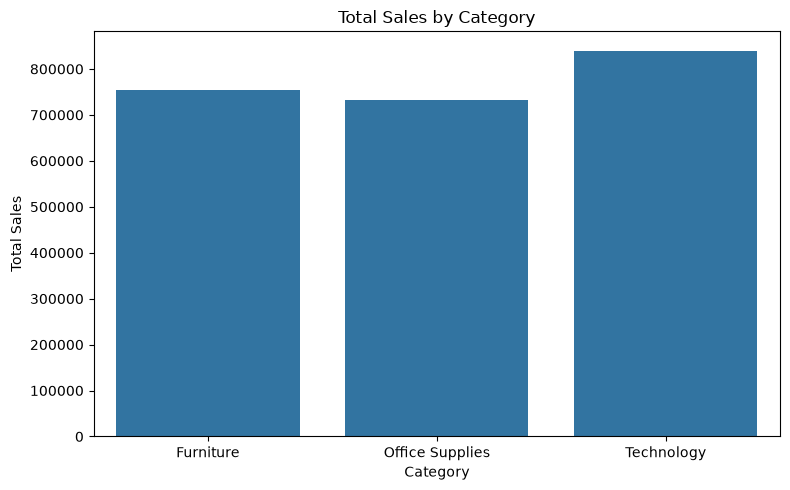

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=category_analysis,
    x="Category",
    y="Total_Sales"
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")

plt.tight_layout()

# Save the chart
plt.savefig("../visualization/category_sales.png", dpi=300)
plt.show()

In [29]:
# Monthly sales and profit analysis

monthly_sales = df.groupby("Year-Month", as_index=False).agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

monthly_sales.head()

,Year-Month,Total_Sales,Total_Profit
0,2023-01,14518.055,2539.3907
1,2023-02,4519.892,862.3084
2,2023-03,56933.909,693.4499
3,2023-04,28295.345,3488.8352
4,2023-05,26319.767,3196.3918


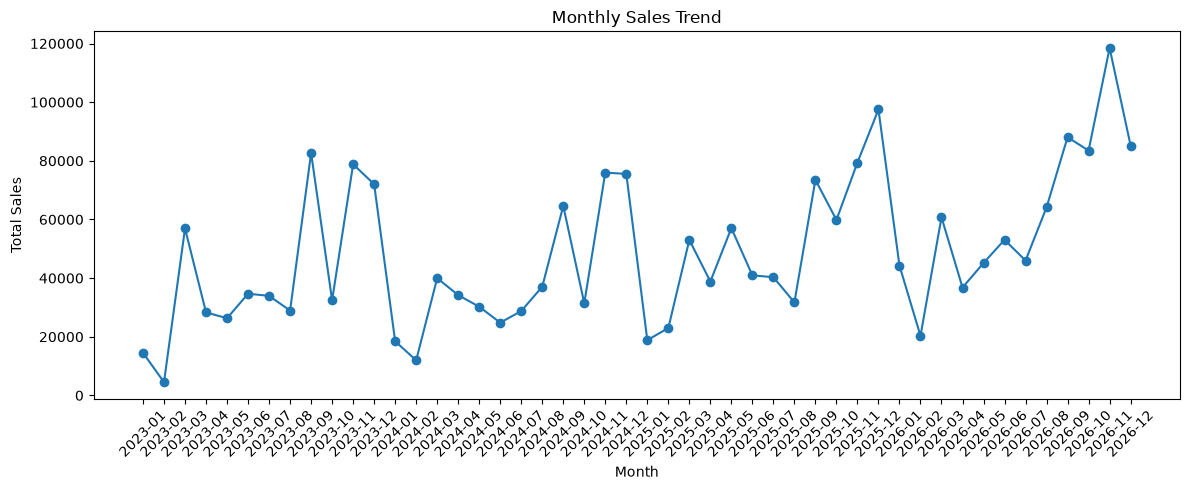

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Year-Month"].astype(str),
    monthly_sales["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)

plt.tight_layout()

# Save chart
plt.savefig("../visualization/monthly_sales.png", dpi=300)

plt.show()

In [31]:
# Top 10 products by sales

top_products = (
    df.groupby("Product Name", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

top_products

,Product Name,Total_Sales,Total_Profit,Total_Quantity
404,Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04,20
649,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7.753039e+03,31
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1.811078e+03,6
785,HON 5400 Series Task Chairs for Big and Tall,21870.576,1.136868e-13,39
685,GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03,37
687,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02,48
804,Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03,38
786,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4.094977e+03,12
682,GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03,27
812,High Speed Automatic Electric Letter Opener,17030.312,-2.620048e+02,11


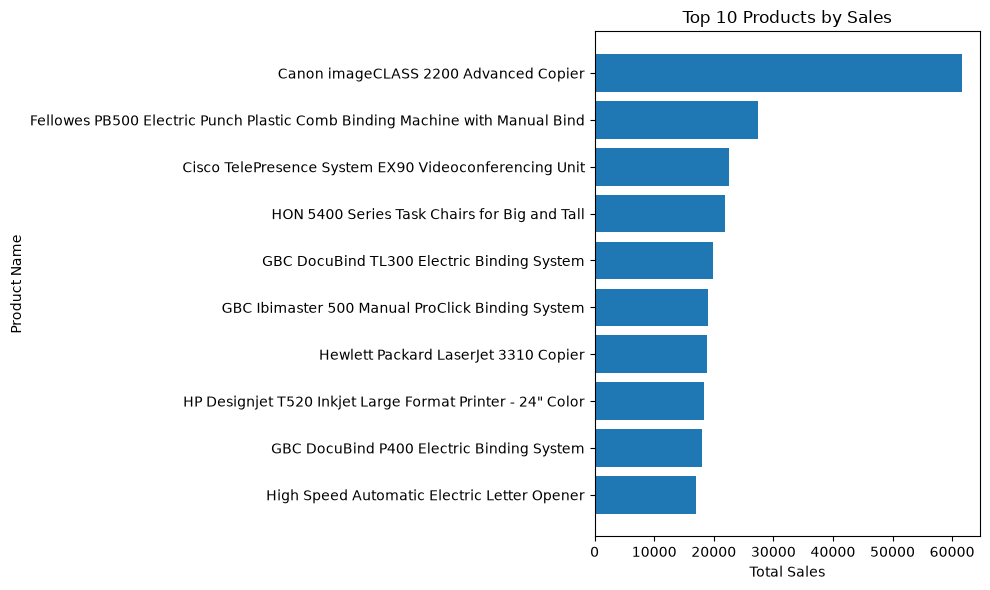

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["Product Name"],
    top_products["Total_Sales"]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Name")

plt.gca().invert_yaxis()

plt.tight_layout()

# Save chart
plt.savefig("../visualization/top_products.png", dpi=300)

plt.show()

In [33]:
# Sales and profit by region

regional_sales = (
    df.groupby("Region", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

regional_sales

,Region,Total_Sales,Total_Profit
3,West,739813.6085,110798.8170
1,East,691828.1680,94883.2603
0,Central,503170.6728,39865.3070
2,South,391721.9050,46749.4303


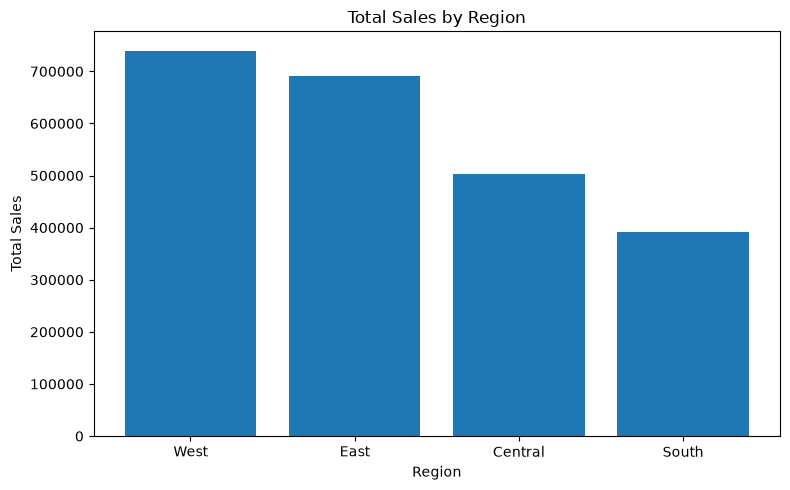

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    regional_sales["Region"],
    regional_sales["Total_Sales"]
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")

plt.tight_layout()

# Save chart
plt.savefig("../visualization/regional_sales.png", dpi=300)

plt.show()


In [35]:
# Number of unique customers

unique_customers = df["Customer ID"].nunique()

unique_customers

804

In [36]:
# Sales and profit by customer

customer_analysis = (
    df.groupby(
        ["Customer ID", "Customer Name"],
        as_index=False
    )
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

customer_analysis.head(10)

,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Quantity
711,SM-20320,Sean Miller,25043.050,-1980.7393,50
752,TC-20980,Tamara Chand,19052.218,8981.3239,42
632,RB-19360,Raymond Buch,15117.339,6976.0959,71
741,TA-21385,Tom Ashbrook,14595.620,4703.7883,36
6,AB-10105,Adrian Barton,14473.571,5444.8055,73
443,KL-16645,Ken Lonsdale,14175.229,806.8550,113
680,SC-20095,Sanjit Chand,14142.334,5757.4119,87
328,HL-15040,Hunter Lopez,12873.298,5622.4292,50
694,SE-20110,Sanjit Engle,12209.438,2650.6769,78
132,CC-12370,Christopher Conant,12129.072,2177.0493,34


In [37]:
# Average Order Value

total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique()

average_order_value = total_sales / total_orders

average_order_value


np.float64(455.2013997847779)

In [38]:
# Customer profit margin

customer_analysis["Profit_Margin"] = (
    customer_analysis["Total_Profit"] /
    customer_analysis["Total_Sales"]
) * 100

customer_analysis.head(10)

,Customer ID,Customer Name,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
711,SM-20320,Sean Miller,25043.050,-1980.7393,50,-7.909337
752,TC-20980,Tamara Chand,19052.218,8981.3239,42,47.140569
632,RB-19360,Raymond Buch,15117.339,6976.0959,71,46.146322
741,TA-21385,Tom Ashbrook,14595.620,4703.7883,36,32.227396
6,AB-10105,Adrian Barton,14473.571,5444.8055,73,37.618950
443,KL-16645,Ken Lonsdale,14175.229,806.8550,113,5.692007
680,SC-20095,Sanjit Chand,14142.334,5757.4119,87,40.710479
328,HL-15040,Hunter Lopez,12873.298,5622.4292,50,43.675127
694,SE-20110,Sanjit Engle,12209.438,2650.6769,78,21.710065
132,CC-12370,Christopher Conant,12129.072,2177.0493,34,17.949018


In [39]:
# Analyze profit by discount level

discount_analysis = (
    df.groupby("Discount", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Discount")
)

discount_analysis

,Discount,Total_Sales,Total_Profit,Total_Quantity
0,0.00,1.105324e+06,326718.5872,18770
1,0.10,5.495250e+04,9099.9700,377
2,0.15,2.755852e+04,1418.9915,198
3,0.20,7.739394e+05,91079.9517,13856
4,0.30,1.044741e+05,-10513.4456,855
5,0.32,1.449346e+04,-2391.1377,105
6,0.40,1.164978e+05,-23086.3742,789
7,0.45,5.484974e+03,-2493.1111,45
8,0.50,5.891854e+04,-20506.4281,241
9,0.60,7.105940e+03,-6164.3472,554


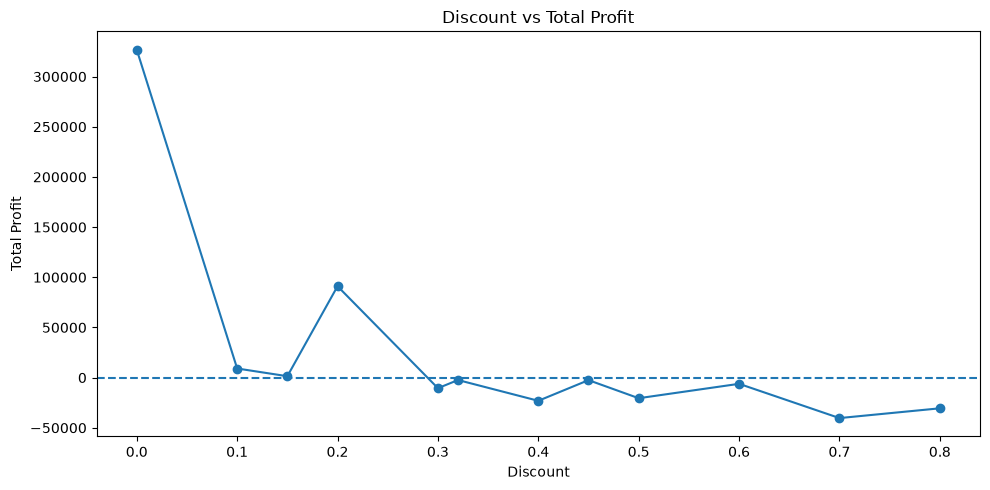

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    discount_analysis["Discount"],
    discount_analysis["Total_Profit"],
    marker="o"
)

plt.axhline(0, linestyle="--")

plt.title("Discount vs Total Profit")
plt.xlabel("Discount")
plt.ylabel("Total Profit")

plt.tight_layout()

plt.savefig("../visualization/discount_vs_profit.png", dpi=300)

plt.show()

In [41]:
# Analyze sales and profit by sub-category

subcategory_analysis = (
    df.groupby("Sub-Category", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

subcategory_analysis

,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
5,Chairs,335768.2490,27223.5323,2431
13,Phones,331842.6400,45050.8265,3357
14,Storage,224644.5540,21285.1115,3191
16,Tables,208020.1820,-17753.2061,1261
3,Binders,207354.8810,31426.1003,6071
11,Machines,189925.0310,3461.9769,442
0,Accessories,167380.3180,41936.6357,2976
6,Copiers,150745.2900,56093.9365,242
4,Bookcases,115361.2043,-3632.0736,878
1,Appliances,108213.1850,18329.4844,1750


In [43]:
# Calculate profit margin for each sub-category

subcategory_analysis["Profit_Margin"] = (
    subcategory_analysis["Total_Profit"]
    / subcategory_analysis["Total_Sales"]
) * 100

subcategory_analysis

,Sub-Category,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
5,Chairs,335768.2490,27223.5323,2431,8.107834
13,Phones,331842.6400,45050.8265,3357,13.575961
14,Storage,224644.5540,21285.1115,3191,9.475018
16,Tables,208020.1820,-17753.2061,1261,-8.534367
3,Binders,207354.8810,31426.1003,6071,15.155708
11,Machines,189925.0310,3461.9769,442,1.822812
0,Accessories,167380.3180,41936.6357,2976,25.054700
6,Copiers,150745.2900,56093.9365,242,37.211071
4,Bookcases,115361.2043,-3632.0736,878,-3.148436
1,Appliances,108213.1850,18329.4844,1750,16.938310


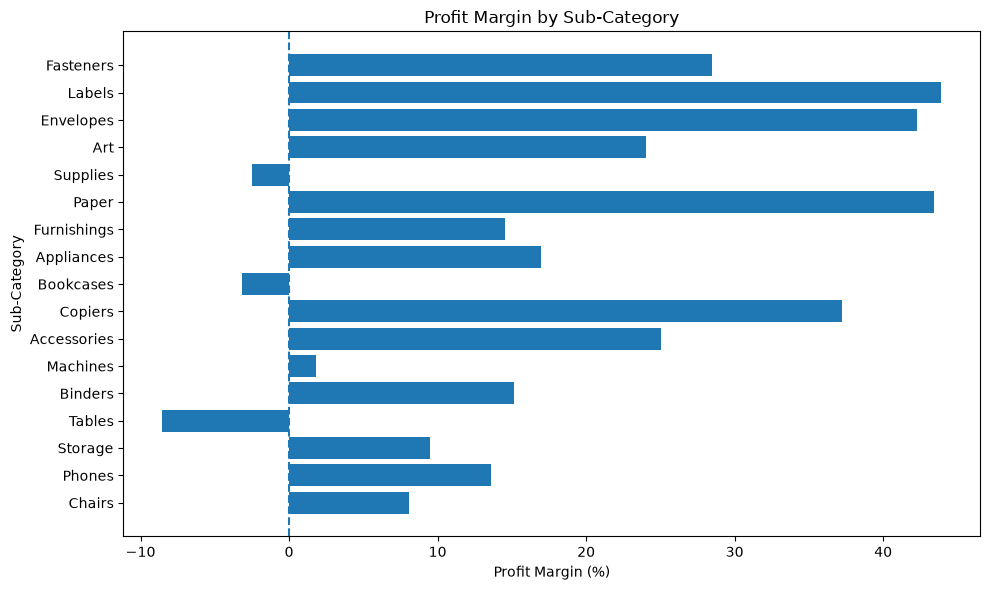

In [44]:
# Sub-category profit margin visualization

plt.figure(figsize=(10, 6))

plt.barh(
    subcategory_analysis["Sub-Category"],
    subcategory_analysis["Profit_Margin"]
)

plt.axvline(0, linestyle="--")

plt.title("Profit Margin by Sub-Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Sub-Category")

plt.tight_layout()

plt.savefig("../visualization/subcategory_profit_margin.png", dpi=300)

plt.show()

# Business Insights

## 1. Sales and Profit Trend
- Sales increased significantly from 2024 to 2026.
- 2026 recorded the highest total sales and total profit.
- Although sales increased in 2026, profit margin decreased slightly compared with 2025.

## 2. Category Performance
- Technology generated the highest sales and profit.
- Office Supplies had the highest quantity sold.
- Furniture generated substantial sales but had a much lower profit margin than the other categories.

## 3. Sub-Category Performance
- Chairs generated the highest sales among the sub-categories.
- Copiers generated the highest total profit.
- Paper and Labels had very high profit margins.
- Tables had a negative profit margin despite generating significant sales.
- Bookcases and Supplies also recorded negative profit margins.

## 4. Discount Analysis
- Lower discount levels were generally associated with positive profitability.
- Higher discount levels showed negative total profit in this dataset.
- This indicates that discount levels should be monitored when evaluating profitability.

## 5. Regional Performance
- The West region generated the highest sales and profit.
- The East region was the second-highest region by sales and profit.
- The Central region generated more sales than the South but lower total profit.

## 6. Customer Analysis
- The dataset contains 804 unique customers.
- Average order value was approximately 455.20.
- Some high-sales customers generated negative profit, showing that customer revenue alone does not indicate profitability.

## 7. Product Performance
- Canon imageCLASS 2200 Advanced Copier generated the highest sales among individual products.
- Some high-sales products generated negative or very low profit.
- Product-level profitability should therefore be considered along with sales performance.